# Técnicas de regularización

El departamento de calidad de una empresa de alimentación se encarga de medir el contenido en grasa de la carne que comercializa. Este estudio se realiza mediante técnicas de analítica química, un proceso relativamente costoso en tiempo y recursos. Una alternativa que permitiría reducir costes y optimizar tiempo es emplear un espectrofotómetro (instrumento capaz de detectar la absorbancia que tiene un material a diferentes tipos de luz en función de sus características) e inferir el contenido en grasa a partir de sus medidas.

Antes de dar por válida esta nueva técnica, la empresa necesita comprobar qué margen de error tiene respecto al análisis químico. Para ello, se mide el espectro de absorbancia a 100 longitudes de onda en 215 muestras de carne, cuyo contenido en grasa se obtiene también por análisis químico, y se entrena un modelo con el objetivo de predecir el contenido en grasa a partir de los valores dados por el espectrofotómetro.

El set de datos contiene 101 columnas. Las 100 primeras, nombradas como V1, ...,V100 recogen el valor de absorbancia para cada una de las 100 longitudes de onda analizadas (predictores), y la columna fat el contenido en grasa medido por técnicas químicas (variable respuesta)

In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option('display.max_columns', None) # Muestra todas las columnas sin truncarlas con "..."

In [2]:
# Código para que no me imprima los warnings
import warnings
from sklearn.exceptions import ConvergenceWarning, DataConversionWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=DataConversionWarning)

In [ ]:
# Carga del dataset

espectros_totales = pd.read_csv("meatspec.csv")
espectros_totales.head(5)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,V41,V42,V43,V44,V45,V46,V47,V48,V49,V50,V51,V52,V53,V54,V55,V56,V57,V58,V59,V60,V61,V62,V63,V64,V65,V66,V67,V68,V69,V70,V71,V72,V73,V74,V75,V76,V77,V78,V79,V80,V81,V82,V83,V84,V85,V86,V87,V88,V89,V90,V91,V92,V93,V94,V95,V96,V97,V98,V99,V100,fat
0,2.61776,2.61814,2.61859,2.61912,2.61981,2.62071,2.62186,2.62334,2.62511,2.62722,2.62964,2.63245,2.63565,2.63933,2.64353,2.64825,2.65350,2.65937,2.66585,2.67281,2.68008,2.68733,2.69427,2.70073,2.70684,2.71281,2.71914,2.72628,2.73462,2.74416,2.75466,2.76568,2.77679,2.78790,2.79949,2.81225,2.82706,2.84356,2.86106,2.87857,2.89497,2.90924,2.92085,2.93015,2.93846,2.94771,2.96019,2.97831,3.00306,3.03506,3.07428,3.11963,3.16868,3.21771,3.26254,3.29988,3.32847,3.34899,3.36342,3.37379,3.38152,3.38741,3.39164,3.39418,3.39490,3.39366,3.39045,3.38541,3.37869,3.37041,3.36073,3.34979,3.33769,3.32443,3.31013,3.29487,3.27891,3.26232,3.24542,3.22828,3.21080,3.19287,3.17433,3.15503,3.13475,3.11339,3.09116,3.06850,3.04596,3.02393,3.00247,2.98145,2.96072,2.94013,2.91978,2.89966,2.87964,2.85960,2.83940,2.81920,22.5
1,2.83454,2.83871,2.84283,2.84705,2.85138,2.85587,2.86060,2.86566,2.87093,2.87661,2.88264,2.88898,2.89577,2.90308,2.91097,2.91953,2.92873,2.93863,2.94929,2.96072,2.97272,2.98493,2.99690,3.00833,3.01920,3.02990,3.04101,3.05345,3.06777,3.08416,3.10221,3.12106,3.13983,3.15810,3.17623,3.19519,3.21584,3.23747,3.25889,3.27835,3.29384,3.30362,3.30681,3.30393,3.29700,3.28925,3.28409,3.28505,3.29326,3.30923,3.33267,3.36251,3.39661,3.43188,3.46492,3.49295,3.51458,3.53004,3.54067,3.54797,3.55306,3.55675,3.55921,3.56045,3.56034,3.55876,3.55571,3.55132,3.54585,3.53950,3.53235,3.52442,3.51583,3.50668,3.49700,3.48683,3.47626,3.46552,3.45501,3.44481,3.43477,3.42465,3.41419,3.40303,3.39082,3.37731,3.36265,3.34745,3.33245,3.31818,3.30473,3.29186,3.27921,3.26655,3.25369,3.24045,3.22659,3.21181,3.19600,3.17942,40.1
2,2.58284,2.58458,2.58629,2.58808,2.58996,2.59192,2.59401,2.59627,2.59873,2.60131,2.60414,2.60714,2.61029,2.61361,2.61714,2.62089,2.62486,2.62909,2.63361,2.63835,2.64330,2.64838,2.65354,2.65870,2.66375,2.66880,2.67383,2.67892,2.68411,2.68937,2.69470,2.70012,2.70563,2.71141,2.71775,2.72490,2.73344,2.74327,2.75433,2.76642,2.77931,2.79272,2.80649,2.82064,2.83541,2.85121,2.86872,2.88905,2.91289,2.94088,2.97325,3.00946,3.04780,3.08554,3.11947,3.14696,3.16677,3.17938,3.18631,3.18924,3.18950,3.18801,3.18498,3.18039,3.17411,3.16611,3.15641,3.14512,3.13241,3.11843,3.10329,3.08714,3.07014,3.05237,3.03393,3.01504,2.99569,2.97612,2.95642,2.93660,2.91667,2.89655,2.87622,2.85563,2.83474,2.81361,2.79235,2.77113,2.75015,2.72956,2.70934,2.68951,2.67009,2.65112,2.63262,2.61461,2.59718,2.58034,2.56404,2.54816,8.4
3,2.82286,2.82460,2.82630,2.82814,2.83001,2.83192,2.83392,2.83606,2.83842,2.84097,2.84374,2.84664,2.84975,2.85307,2.85661,2.86038,2.86437,2.86860,2.87308,2.87789,2.88301,2.88832,2.89374,2.89917,2.90457,2.90991,2.91521,2.92043,2.92565,2.93082,2.93604,2.94128,2.94658,2.95202,2.95777,2.96419,2.97159,2.98045,2.99090,3.00284,3.01611,3.03048,3.04579,3.06194,3.07889,3.09686,3.11629,3.13775,3.16217,3.19068,3.22376,3.26172,3.30379,3.34793,3.39093,3.42920,3.45998,3.48227,3.49687,3.50558,3.51026,3.51221,3.51215,3.51036,3.50682,3.50140,3.49398,3.48457,3.47333,3.46041,3.44595,3.43005,3.41285,3.39450,3.37511,3.35482,3.33376,3.31204,3.28986,3.26730,3.24442,3.22117,3.19757,3.17357,3.14915,3.12429,3.09908,3.07366,3.04825,3.02308,2.99820,2.97367,2.94951,2.92576,2.90251,2.87988,2.85794,2.83672,2.81617,2.79622,5.9
4,2.78813,2.78989,2.79167,2.79350,2.79538,2.79746,2.79984,2.80254,2.80553,2.80890,2.81272,2.81704,2.82184,2.82710,2.83294,2.83945,2.84664,2.85458,2.86331,2.87280,2.88291,2.89335,2.90374,2.91371,2.92305,2.93187,2.94060,2.94986,2.96035,2.97241,2.98606,3.00097,3.01652,3.03220,3.04793,3.06413,3.08153,3.10078,3.12185,3.14371,3.16510,3.18470,3.20140,3.21477,3.22544,3.23505,3.24586

In [4]:
espectros_totales.info()

<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Columns: 101 entries, V1 to fat
dtypes: float64(101)
memory usage: 169.8 KB


In [5]:
espectros_totales.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,V41,V42,V43,V44,V45,V46,V47,V48,V49,V50,V51,V52,V53,V54,V55,V56,V57,V58,V59,V60,V61,V62,V63,V64,V65,V66,V67,V68,V69,V70,V71,V72,V73,V74,V75,V76,V77,V78,V79,V80,V81,V82,V83,V84,V85,V86,V87,V88,V89,V90,V91,V92,V93,V94,V95,V96,V97,V98,V99,V100,fat
count,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000
mean,2.808561,2.811137,2.813727,2.816363,2.819098,2.821983,2.825064,2.828375,2.831943,2.835813,2.839957,2.844390,2.849152,2.854288,2.859844,2.865844,2.872291,2.879244,2.886728,2.894691,2.902986,2.911358,2.919562,2.927454,2.935059,2.942558,2.950275,2.958583,2.967758,2.977881,2.988772,3.000071,3.011461,3.022919,3.034826,3.047814,3.062523,3.078830,3.096211,3.113879,3.130891,3.146409,3.160014,3.171948,3.183190,3.195273,3.209969,3.229324,3.254360,3.285806,3.323817,3.367577,3.414949,3.462492,3.506207,3.542778,3.570628,3.590259,3.603489,3.612217,3.617985,3.621690,3.623647,3.623836,3.622136,3.618438,3.612758,3.605205,3.595975,3.585247,3.573175,3.559896,3.545537,3.530208,3.513990,3.496981,3.479365,3.461379,3.443216,3.424906,3.406406,3.387609,3.368399,3.348625,3.328123,3.306856,3.284976,3.262852,3.240918,3.219482,3.198627,3.178262,3.158254,3.138534,3.119104,3.099971,3.081070,3.062290,3.043548,3.024895,18.142326
std,0.410793,0.413352,0.415906,0.418465,0.421040,0.423635,0.426245,0.428866,0.431510,0.434195,0.436906,0.439653,0.442446,0.445303,0.448239,0.451257,0.454356,0.457546,0.460843,0.464272,0.467797,0.471355,0.474864,0.478260,0.481541,0.484774,0.488073,0.491629,0.495564,0.499945,0.504694,0.509635,0.514550,0.519277,0.523824,0.528329,0.532875,0.537384,0.541553,0.544953,0.547071,0.547488,0.546067,0.543051,0.539009,0.534691,0.530815,0.527899,0.526103,0.525422,0.525806,0.527147,0.529258,0.531843,0.534567,0.537113,0.539249,0.540874,0.542105,0.542989,0.543699,0.544263,0.544765,0.545177,0.545499,0.545687,0.545771,0.545746,0.545690,0.545600,0.545468,0.545309,0.545167,0.545045,0.544887,0.544649,0.544448,0.544290,0.544269,0.544326,0.544481,0.544677,0.544868,0.544988,0.544925,0.544640,0.544125,0.543489,0.542884,0.542428,0.542146,0.541957,0.541776,0.541519,0.541135,0.540563,0.539730,0.538586,0.537108,0.535354,12.740297
min,2.066420,2.065830,2.065180,2.064650,2.064170,2.063730,2.063400,2.063140,2.063010,2.063170,2.063470,2.063870,2.064340,2.064930,2.065720,2.066730,2.067940,2.069370,2.070920,2.072770,2.074890,2.077180,2.079520,2.081840,2.084160,2.086460,2.088710,2.090840,2.092890,2.094780,2.096610,2.098490,2.100660,2.103470,2.107220,2.112240,2.119080,2.127810,2.138550,2.151380,2.166190,2.182860,2.201280,2.221350,2.243080,2.266630,2.292410,2.321410,2.354020,2.391010,2.432530,2.477950,2.525360,2.571700,2.613490,2.648050,2.674350,2.693320,2.706750,2.716380,2.723550,2.728830,2.732510,2.734560,2.734880,2.733350,2.729970,2.724810,2.717970,2.709590,2.699810,2.688760,2.676

## Estudiar correlaciones correlaciones

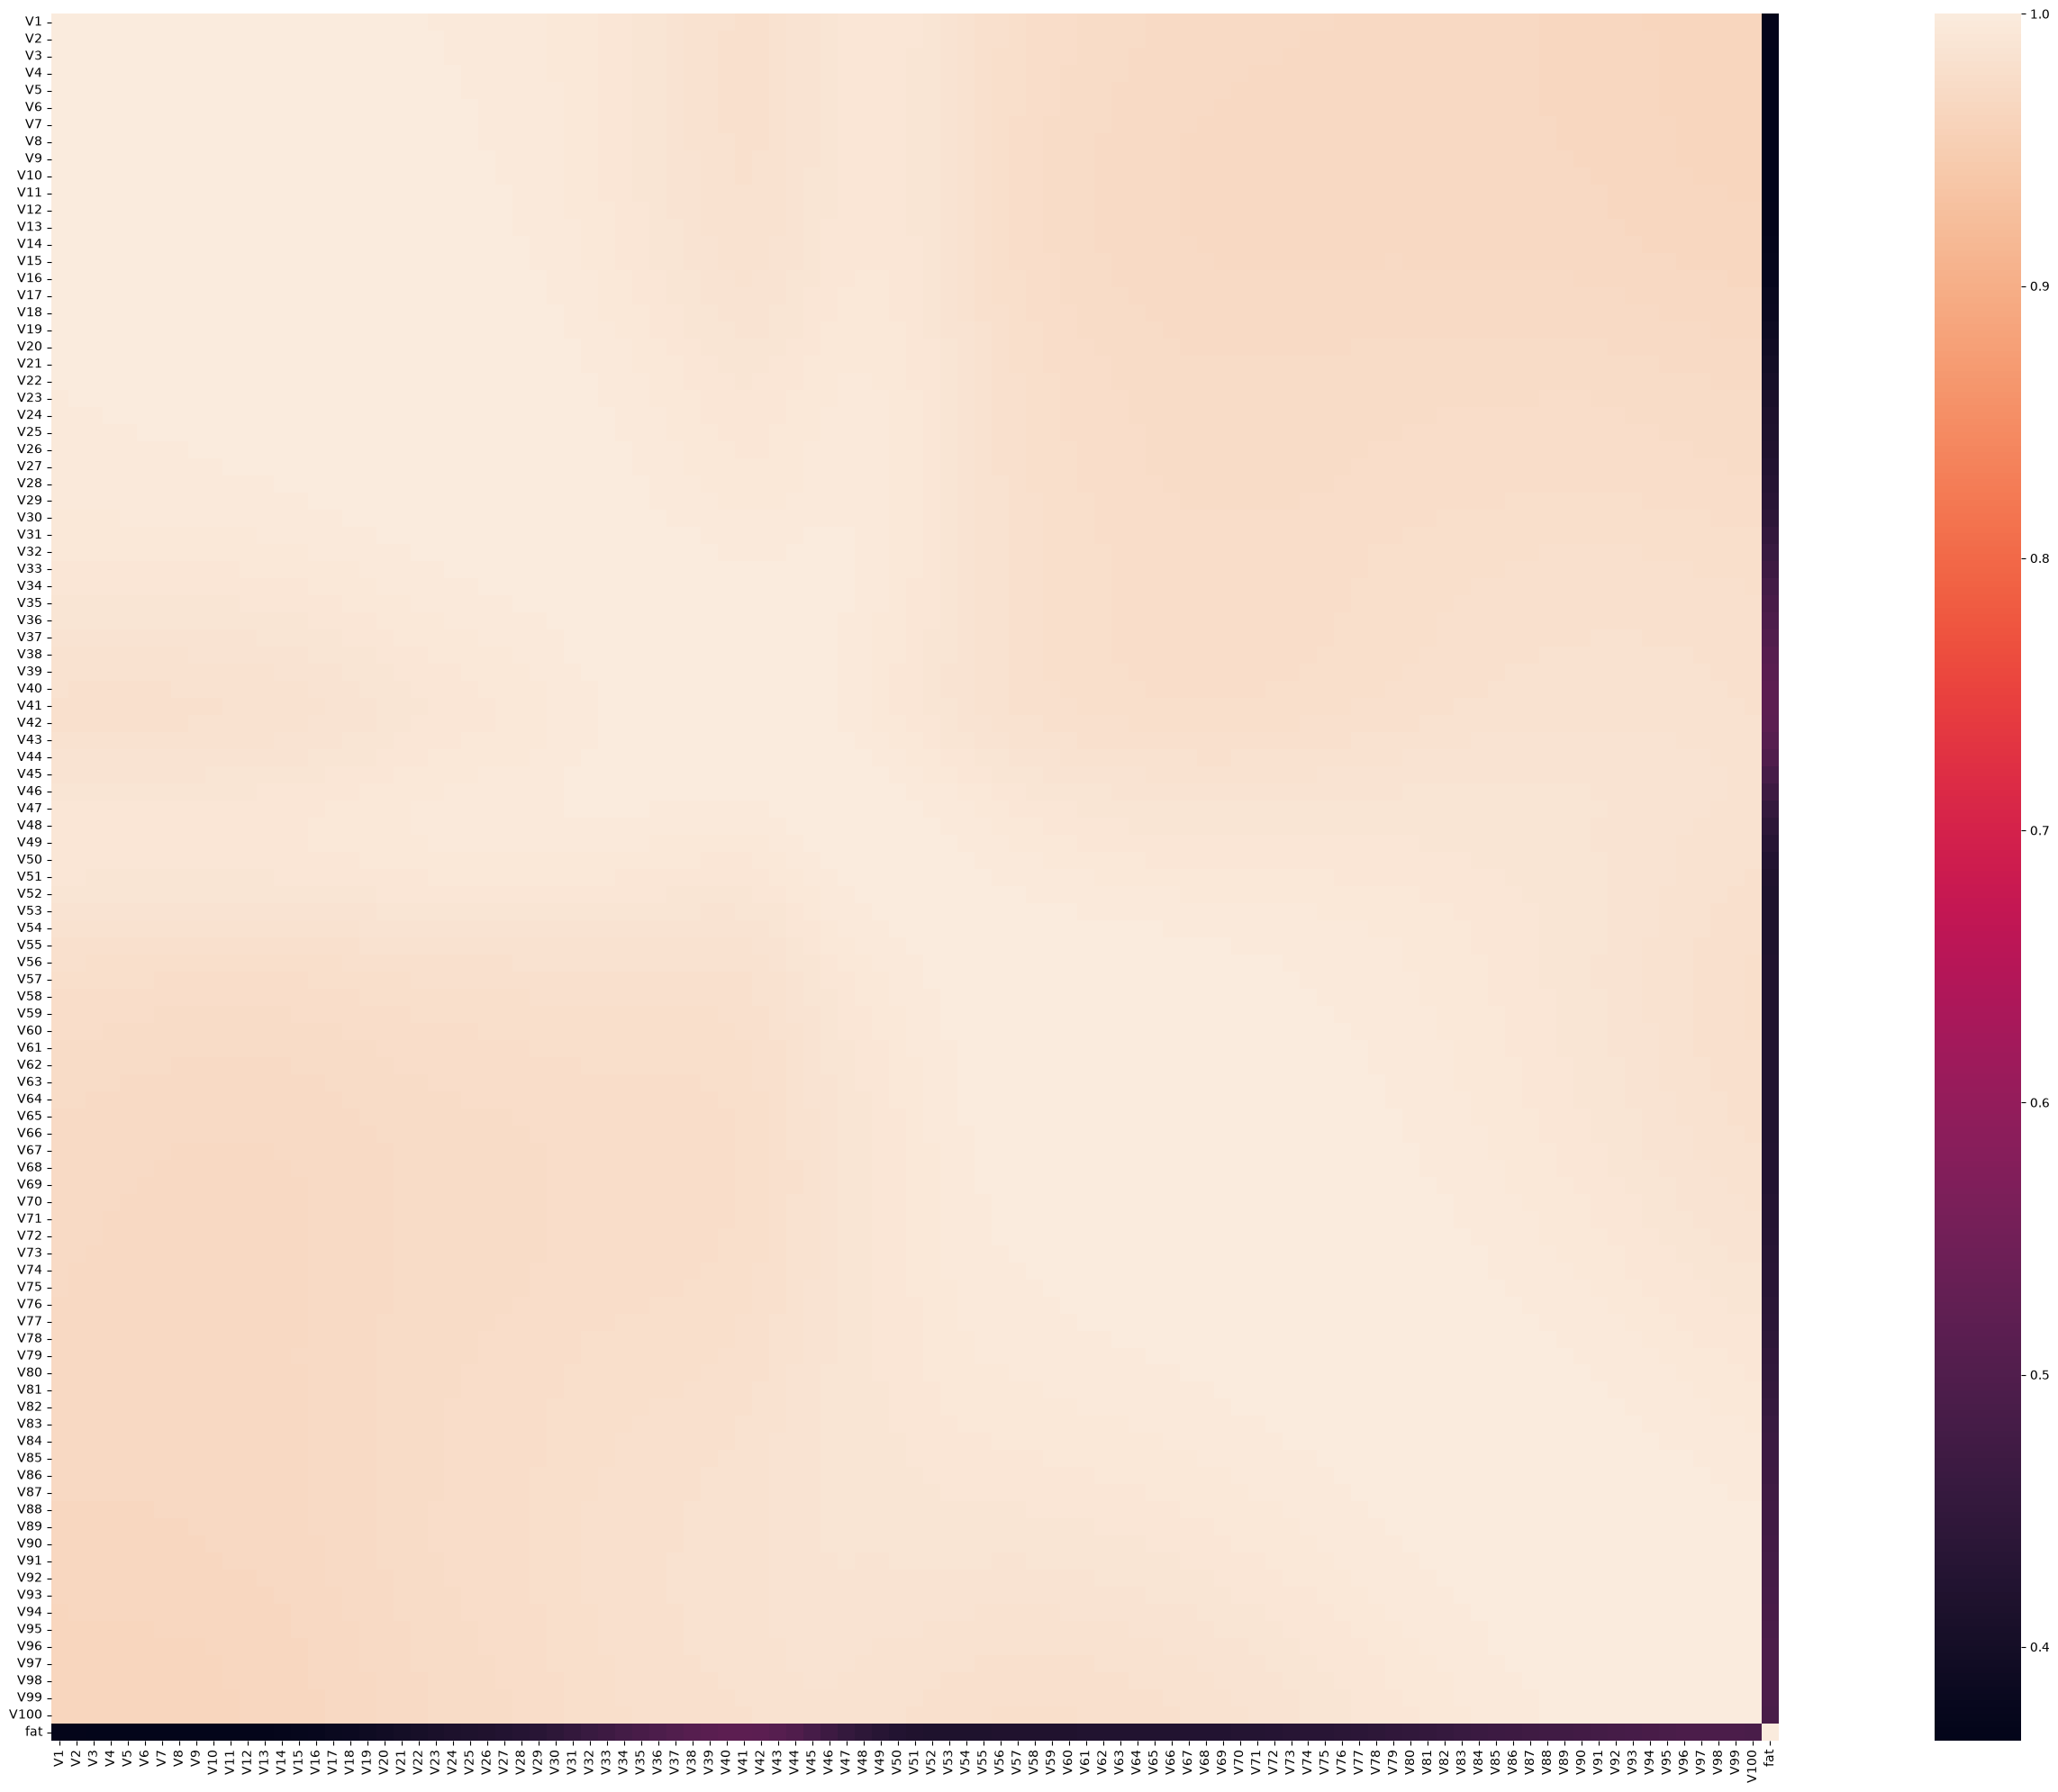

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = [f"V{i}" for i in range(1, 101)] + ["fat"]   
corr = espectros_totales[cols].corr()

plt.figure(figsize=(35, 20))
sns.heatmap(corr, cmap="rocket", square=True)
plt.tight_layout()
plt.show()

In [7]:
## Preparación de los datos
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = espectros_totales.drop(columns="fat")
y = espectros_totales["fat"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size   = 0.7, random_state = 42, shuffle = True)

# Estandarización (Muy importante en los modelos con regularizacion)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)

X_test_scaled = scaler.transform(X_test)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

### Modelo de regresión lineal simple

In [8]:
from sklearn.linear_model import LinearRegression

modelo_lin_reg_mult = LinearRegression()
modelo_lin_reg_mult.fit(X=X_train_scaled, y=y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](100,)","[ 5400.54,-8604.45, 4994.74,..., 4812.07,-1314.52, 1129.4 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](100,)","['V1','V2','V3',...,'V98','V99','V100']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,18.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,100
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(82)


Coeficientes del modelo:

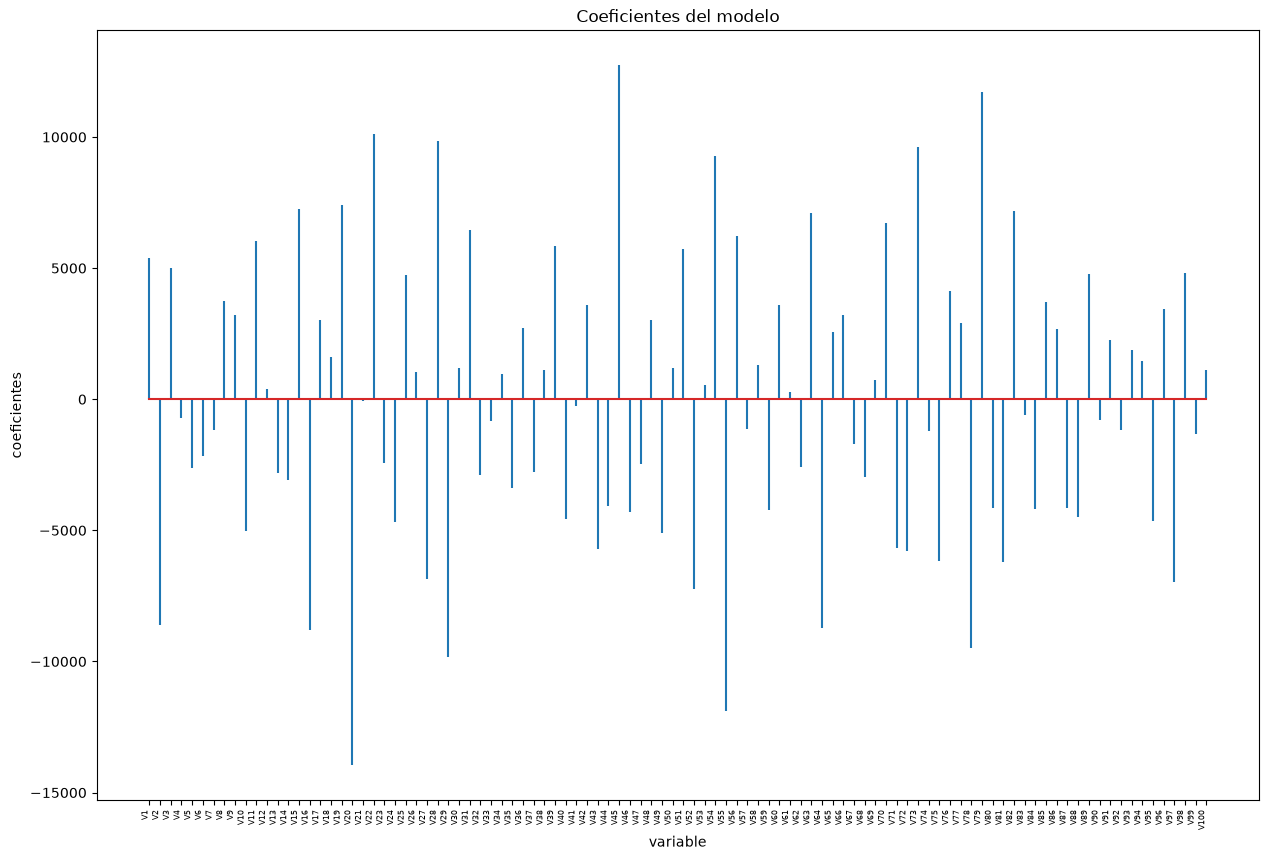

In [9]:
df_coeficientes = pd.DataFrame({'predictor': X_train.columns,'coef': modelo_lin_reg_mult.coef_.flatten()})

fig, ax = plt.subplots(figsize=(15, 10))
ax.stem(df_coeficientes.predictor, df_coeficientes.coef, markerfmt=' ')
plt.xticks(rotation=90, ha='right', size=6)
ax.set_xlabel('variable')
ax.set_ylabel('coeficientes')
ax.set_title('Coeficientes del modelo');

Predicciones

In [10]:

predicciones = modelo_lin_reg_mult.predict(X=X_test_scaled)
predicciones = predicciones.flatten()
predicciones[:10]

array([10.2225943 , 38.62342244, 16.05177364,  7.23603146,  5.82811281,
       29.76261968, 35.26071964,  7.59407314, 16.45439538, 15.93390842])

Error del test del modelo

In [11]:
from sklearn.metrics import root_mean_squared_error, mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_true=y_test, y_pred=predicciones)
rmse = root_mean_squared_error(y_true=y_test, y_pred=predicciones)
msa = mean_absolute_error(y_true=y_test, y_pred=predicciones)

print(f"El error (mse) de test es: {round(mse,2)}")
print(f"El error (rmse) de test es: {round(rmse,2)}")
print(f"El error (msa) de test es: {round(msa,2)}")


El error (mse) de test es: 5.85
El error (rmse) de test es: 2.42
El error (msa) de test es: 1.74


## Regularización con Ridge

In [12]:
from sklearn.linear_model import Ridge
from sklearn.linear_model import RidgeCV

# Lo primero que hacemos es entrenar modelos con ridge con diferentes valores de alpha y evaluarlos por validación cruzada
modelo_ridgecv = RidgeCV(
            alphas           = np.logspace(-20, 2, 200),
            scoring          ='neg_root_mean_squared_error',
            fit_intercept    = True,
            store_cv_results = True
         )

_ = modelo_ridgecv.fit(X = X_train_scaled, y = y_train)

Por defecto, RidgeCV hace validación cruzada leave-one-out (LOO): cada observación queda fuera una vez y el modelo se evalúa con ella. Normalmente LOO es muy costoso, pero en ridge existe una fórmula cerrada que lo calcula de forma muy eficiente, sin reentrenar n veces

Podemos sacar el alpha que minimiza el error entre los conjuntos de entrenamiento:

In [13]:
modelo_ridgecv.alpha_        # el α elegido (el de menor RMSE en CV)

3.001835813575592e-05

Entrenamos el modelo con el valor de alpha seleccionado como mejor con el conjunto de Test y medimos el rendimiento del modelo frente a datos desconocidos

In [14]:
# Hacemos el modelo con regularización con el valor de alpha que reduce más el error respecto al modelo sin regularización

# Train the model  
ridgeR = Ridge(alpha = modelo_ridgecv.alpha_) 
ridgeR.fit(X_train_scaled, y_train) 

print("Train RMSE: %0.4f" % root_mean_squared_error(y_train, ridgeR.predict(X_train_scaled)))
print("Test RMSE: %0.4f" % root_mean_squared_error(y_test, ridgeR.predict(X_test_scaled)))

Train RMSE: 1.8496
Test RMSE: 2.2619


Analizamos cómo han cambiado los coeficientes con la regularización

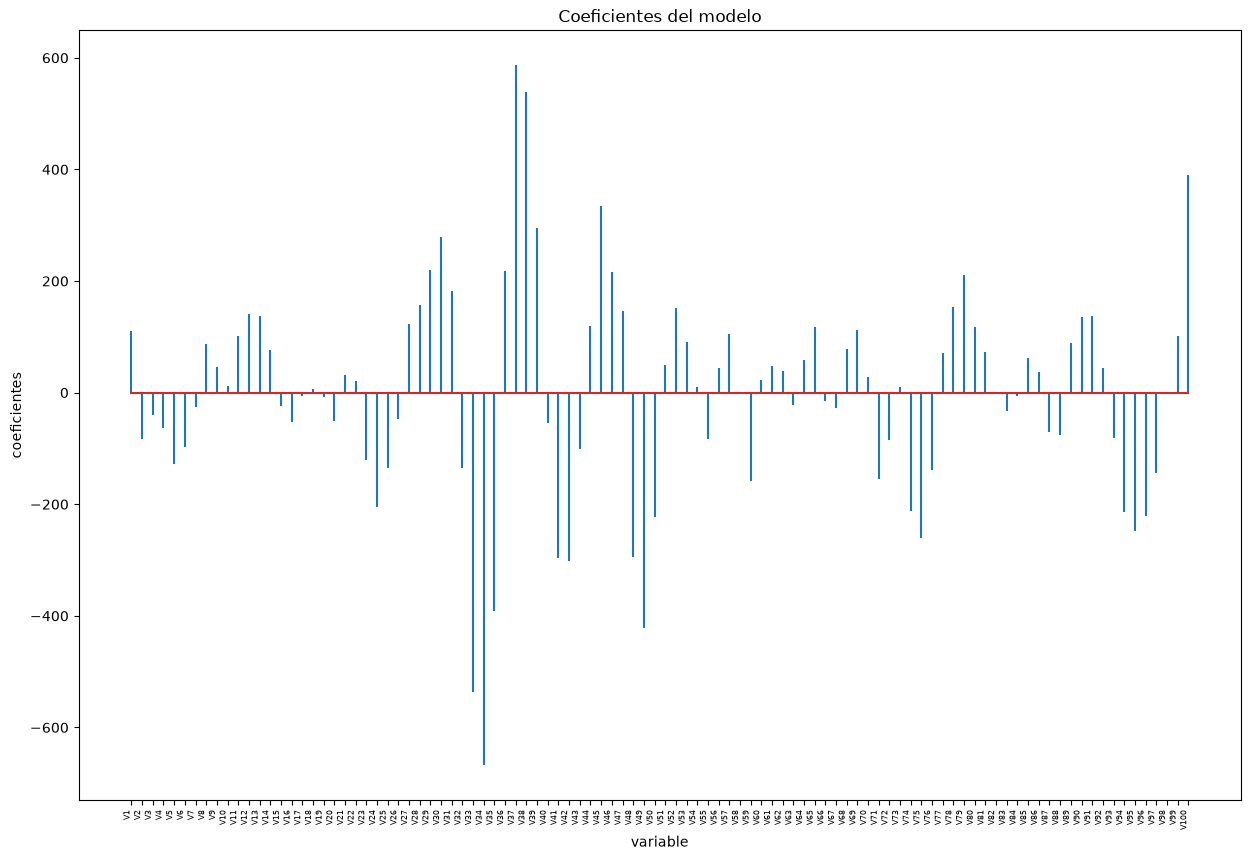

In [15]:
df_coeficientes = pd.DataFrame({'predictor': X_train.columns,'coef':ridgeR.coef_.flatten()})

fig, ax = plt.subplots(figsize=(15, 10))
ax.stem(df_coeficientes.predictor, df_coeficientes.coef, markerfmt=' ')
plt.xticks(rotation=90, ha='right', size=6)
ax.set_xlabel('variable')
ax.set_ylabel('coeficientes')
ax.set_title('Coeficientes del modelo');

Evolución de los coeficientes en función de cómo cambia el alpha

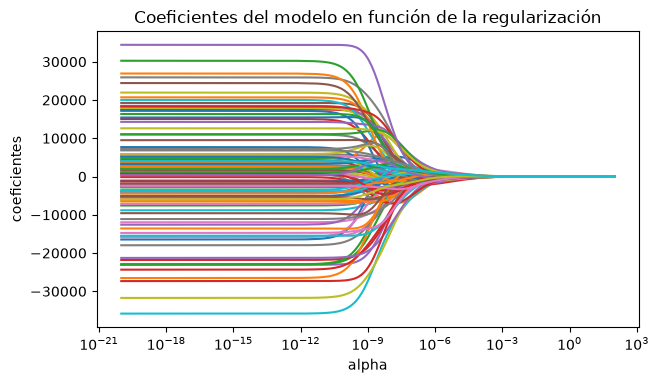

In [16]:
alphas = modelo_ridgecv.alphas
coefs = []

for alpha in alphas:
    modelo = Ridge(alpha=alpha, fit_intercept=True)
    modelo.fit(X_train_scaled, y_train)
    coefs.append(modelo.coef_.flatten())

fig, ax = plt.subplots(figsize=(7, 3.84))
ax.plot(alphas, coefs)
ax.set_xscale('log')
ax.set_xlabel('alpha')
ax.set_ylabel('coeficientes')
ax.set_title('Coeficientes del modelo en función de la regularización');
plt.axis('tight')
plt.show()

Evolución del error en función de alpha

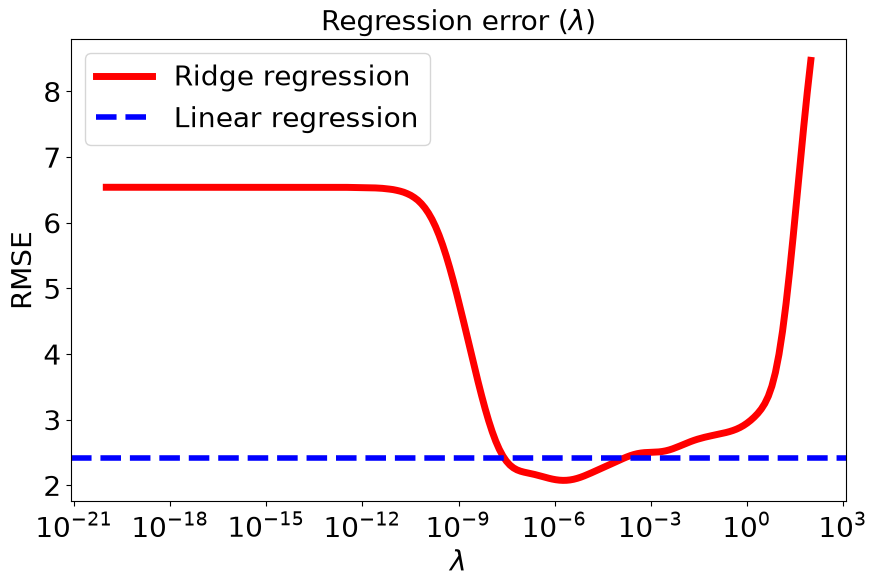

In [17]:
# recuperamos el mean squared error del modelo de regresión lineal sin regularizacion
baseline_error = root_mean_squared_error(y_true=y_test, y_pred=predicciones)

err_ridge = []
baseline = []
for a in alphas: # Para cada valor de alpha, entrenamos un modelo de Ridge
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_scaled, y_train)  
    y_pred = ridge.predict(X_test_scaled) # Calculamos las predicciones
    ridge_error = root_mean_squared_error(y_pred, y_test) # calculamos el error del conjunto de test
    err_ridge.append(ridge_error) # Guardamos el error en una lista


    # Representación gráfica de la evolución del mean squared error en función de alpha

fig, ax = plt.subplots(figsize=(10, 6))
font = 20

ax.plot(alphas, err_ridge, linewidth=5, color="red", label="Ridge regression")
ax.axhline(baseline_error, linewidth=4, linestyle="--", color="blue", label="Linear regression")
ax.set_xscale("log")
ax.set_xlabel(r"$\lambda$", fontsize=font)
ax.set_ylabel("RMSE", fontsize=font)
ax.set_title(r"Regression error ($\lambda$)", fontsize=font)
ax.tick_params(labelsize=font)
ax.legend(fontsize=font)
plt.show()

No debemos seleccionar este valor de alpha para llevar un modelo a producción porque sobreestimará el rendimiento del modelo.

## Regularización con Lasso

In [18]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import LassoCV

# Creación y entrenamiento del modelo (con búsqueda por CV del valor óptimo alpha)
# Por defecto LassoCV utiliza el mean squared error
modeloLasso = LassoCV(
            alphas = np.logspace(-5, 3, 200),
            cv = 5, max_iter= 10000).fit(X = X_train_scaled, y = y_train)


Elegimos el mejor valor de alpha según el proceso de cross validation sobre el conjunto de entrenamiento

In [19]:
modeloLasso.alpha_        # el α elegido (el de menor RMSE en CV)

np.float64(1e-05)

Entrenamos el modelo con el valor de alpha seleccionado como mejor con el conjunto de Test y medimos el rendimiento del modelo frente a datos desconocidos

In [20]:
# Hacemos el modelo con regularización con el valor de alpha que reduce más el error respecto al modelo sin regularización

# Train the model  
lassoR = Lasso(alpha = modeloLasso.alpha_) 
lassoR.fit(X_train_scaled, y_train) 

print("Train RMSE: %0.4f" % root_mean_squared_error(y_train, lassoR.predict(X_train_scaled)))
print("Test RMSE: %0.4f" % root_mean_squared_error(y_test, lassoR.predict(X_test_scaled)))

Train RMSE: 4.8235
Test RMSE: 4.9008


Analizamos cómo han cambiado los coeficientes con la regularización

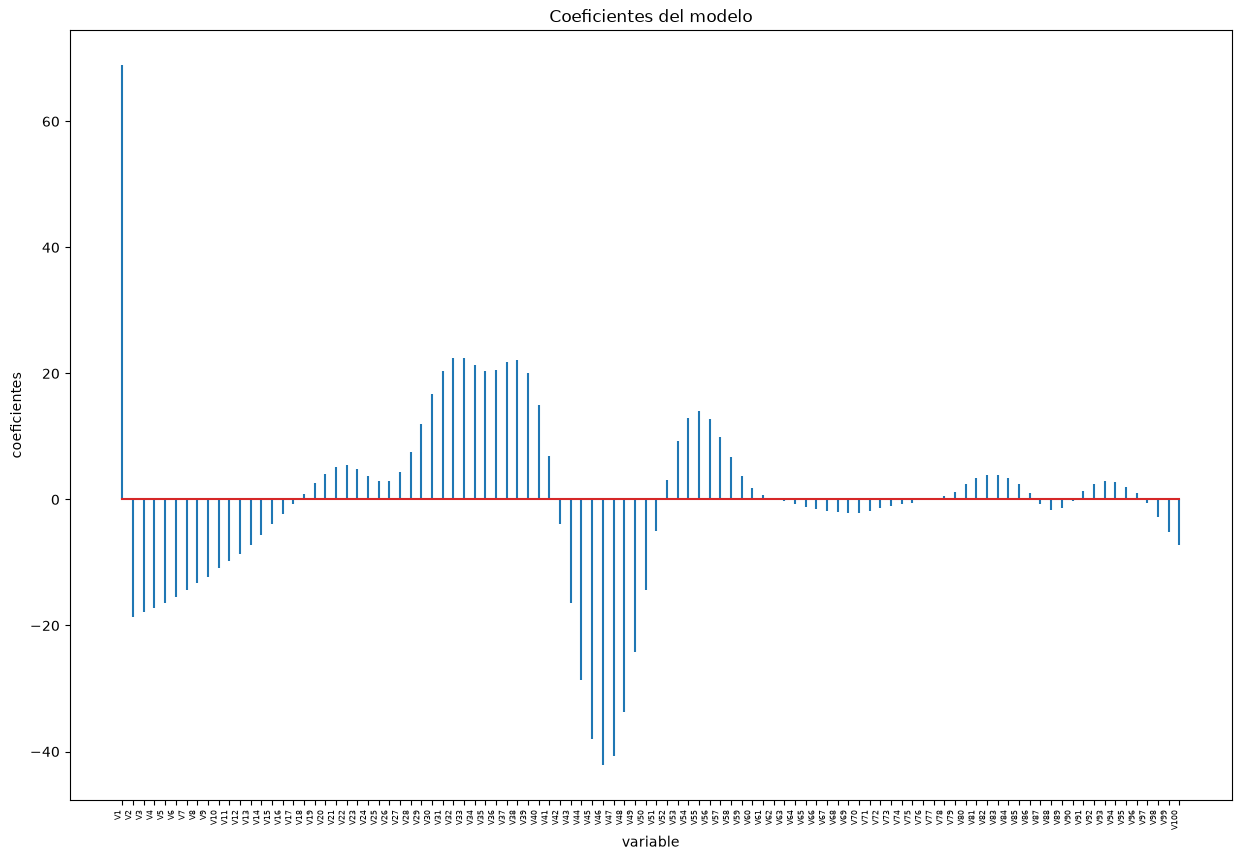

In [21]:
df_coeficientes = pd.DataFrame({'predictor': X_train.columns,'coef':lassoR.coef_.flatten()})

fig, ax = plt.subplots(figsize=(15, 10))
ax.stem(df_coeficientes.predictor, df_coeficientes.coef, markerfmt=' ')
plt.xticks(rotation=90, ha='right', size=6)
ax.set_xlabel('variable')
ax.set_ylabel('coeficientes')
ax.set_title('Coeficientes del modelo');

Evolución de los coeficientes en función de cómo cambia el alpha

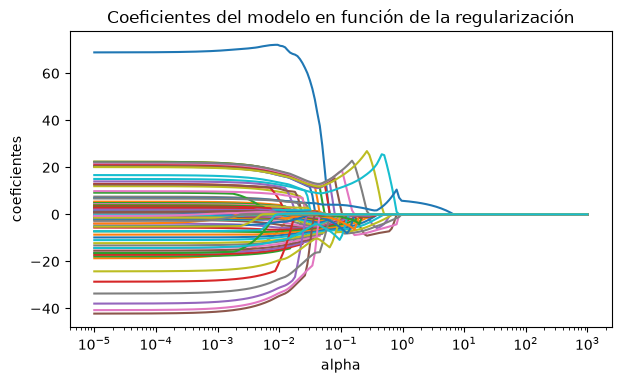

In [22]:
alphas = modeloLasso.alphas
coefs = []

for alpha in alphas:
    modelo = Lasso(alpha=alpha, fit_intercept=True)
    modelo.fit(X_train_scaled, y_train)
    coefs.append(modelo.coef_.flatten())

fig, ax = plt.subplots(figsize=(7, 3.84))
ax.plot(alphas, coefs)
ax.set_xscale('log')
ax.set_xlabel('alpha')
ax.set_ylabel('coeficientes')
ax.set_title('Coeficientes del modelo en función de la regularización');
plt.axis('tight')
plt.show()

Evolución del error en función del valor de alpha

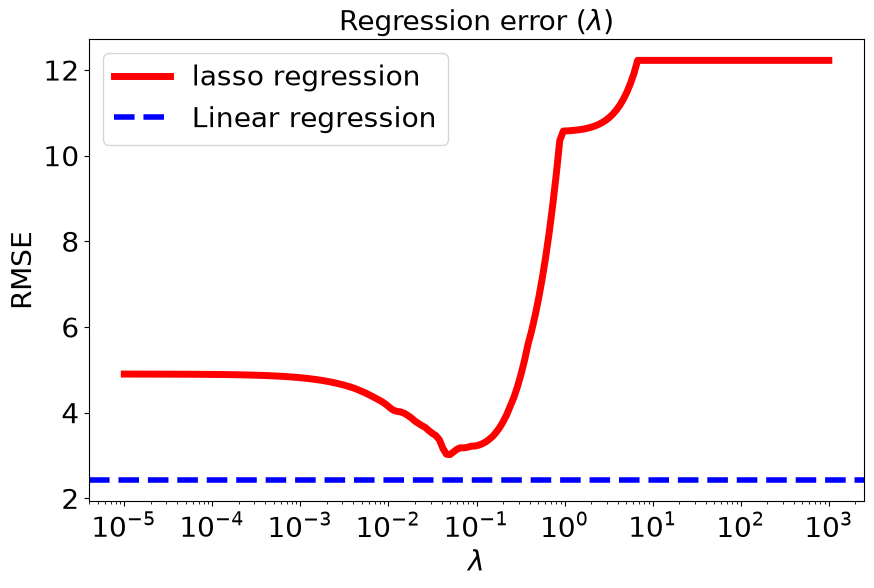

In [23]:
# recuperamos el mean squared error del modelo de regresión lineal sin regularizacion
baseline_error = root_mean_squared_error(y_true=y_test, y_pred=predicciones)

err_lasso = []
baseline = []
for a in alphas: # Para cada valor de alpha, entrenamos un modelo de Ridge
    lasso = Lasso(alpha=a)
    lasso.fit(X_train_scaled, y_train)  
    y_pred = lasso.predict(X_test_scaled) # Calculamos las predicciones
    lasso_error = root_mean_squared_error(y_pred, y_test) # calculamos el error del conjunto de test
    err_lasso.append(lasso_error) # Guardamos el error en una lista


    # Representación gráfica de la evolución del mean squared error en función de alpha

fig, ax = plt.subplots(figsize=(10, 6))
font = 20

ax.plot(alphas, err_lasso, linewidth=5, color="red", label="lasso regression")
ax.axhline(baseline_error, linewidth=4, linestyle="--", color="blue", label="Linear regression")
ax.set_xscale("log")
ax.set_xlabel(r"$\lambda$", fontsize=font)
ax.set_ylabel("RMSE", fontsize=font)
ax.set_title(r"Regression error ($\lambda$)", fontsize=font)
ax.tick_params(labelsize=font)
ax.legend(fontsize=font)
plt.show()

## Regularización con Elastic Net

In [24]:
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import ElasticNetCV

elastic_net = ElasticNetCV(alphas=[0.001, 0.01, 0.1, 1, 10],
                           l1_ratio=[0.1, 0.5, 0.9], cv=5, max_iter=10000)
elastic_net.fit(X_train_scaled, y_train)

,"l1_ratio l1_ratio: float or list of float, default=0.5Float between 0 and 1 passed to ElasticNet (scaling betweenl1 and l2 penalties). For ``l1_ratio = 0``the penalty is an L2 penalty. For ``l1_ratio = 1`` it is an L1 penalty.For ``0 < l1_ratio < 1``, the penalty is a combination of L1 and L2This parameter can be a list, in which case the differentvalues are tested by cross-validation and the one giving the bestprediction score is used. Note that a good choice of list ofvalues for l1_ratio is often to put more values close to 1(i.e. Lasso) and less close to 0 (i.e. Ridge), as in ``[.1, .5, .7,.9, .95, .99, 1]``.","[0.1, 0.5, ...]"
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path, used for each l1_ratio.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.","[0.001, 0.01, ...]"
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"verbose verbose: bool or int, default=0Amount of verbosity.",0
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


Visualizamos cuales son los valores de alpha y l1_ratio (proporción de L1) que minimizan el error

In [25]:
print(f"alpha elegido: {elastic_net.alpha_}")        
print(f"l1_ratio elegido: {elastic_net.l1_ratio_}")  

alpha elegido: 0.001
l1_ratio elegido: 0.9


Ajustamos el modelo con los hiperparámetros seleccionados

In [26]:
elasticR = ElasticNet(alpha = elastic_net.alpha_, l1_ratio = elastic_net.l1_ratio_, max_iter = 10000) 
elasticR.fit(X_train_scaled, y_train) 

print("Train RMSE: %0.4f" % root_mean_squared_error(y_train, elasticR.predict(X_train_scaled)))
print("Test RMSE: %0.4f" % root_mean_squared_error(y_test, elasticR.predict(X_test_scaled)))

Train RMSE: 2.9071
Test RMSE: 2.7841


Visualizamos los coeficientes del modelo

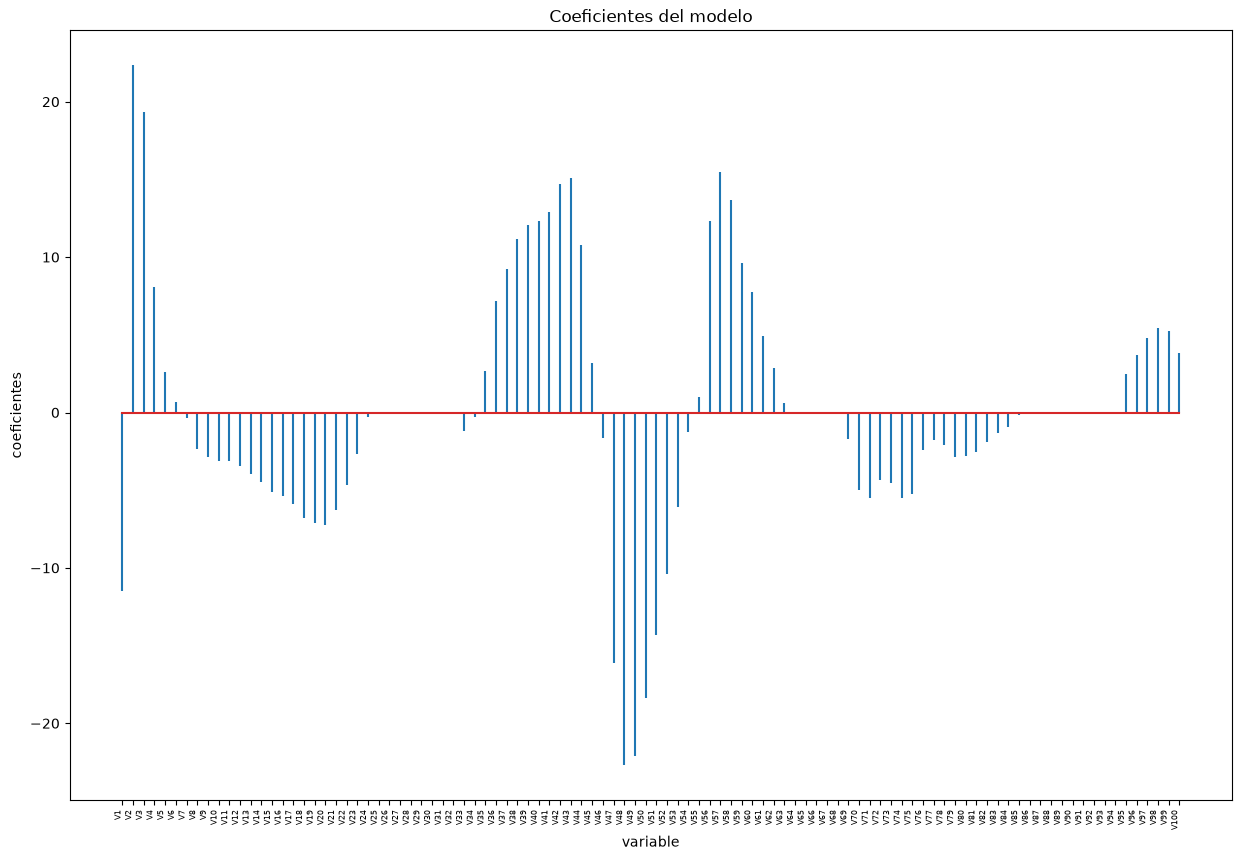

In [27]:
df_coeficientes = pd.DataFrame({'predictor': X_train.columns,'coef':elasticR.coef_.flatten()})

fig, ax = plt.subplots(figsize=(15, 10))
ax.stem(df_coeficientes.predictor, df_coeficientes.coef, markerfmt=' ')
plt.xticks(rotation=90, ha='right', size=6)
ax.set_xlabel('variable')
ax.set_ylabel('coeficientes')
ax.set_title('Coeficientes del modelo');

Visualizamos la evolución de los coeficientes en función de alpha

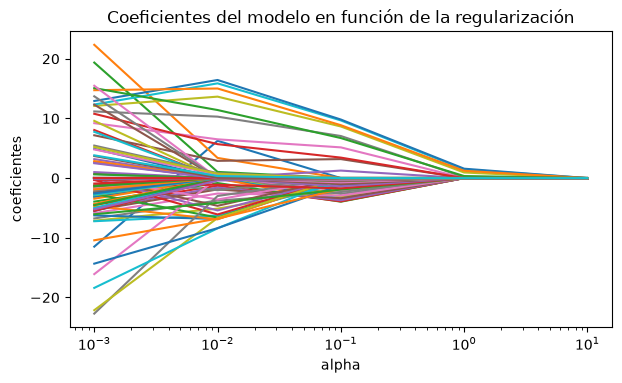

In [28]:
alphas = elastic_net.alphas
coefs = []

for alpha in alphas:
    modelo = ElasticNet(alpha=alpha, l1_ratio=elastic_net.l1_ratio_, fit_intercept=True, max_iter=10000)
    modelo.fit(X_train_scaled, y_train)
    coefs.append(modelo.coef_.flatten())

fig, ax = plt.subplots(figsize=(7, 3.84))
ax.plot(alphas, coefs)
ax.set_xscale('log')
ax.set_xlabel('alpha')
ax.set_ylabel('coeficientes')
ax.set_title('Coeficientes del modelo en función de la regularización');
plt.axis('tight')
plt.show()

Visualizamos el error en función de alpha

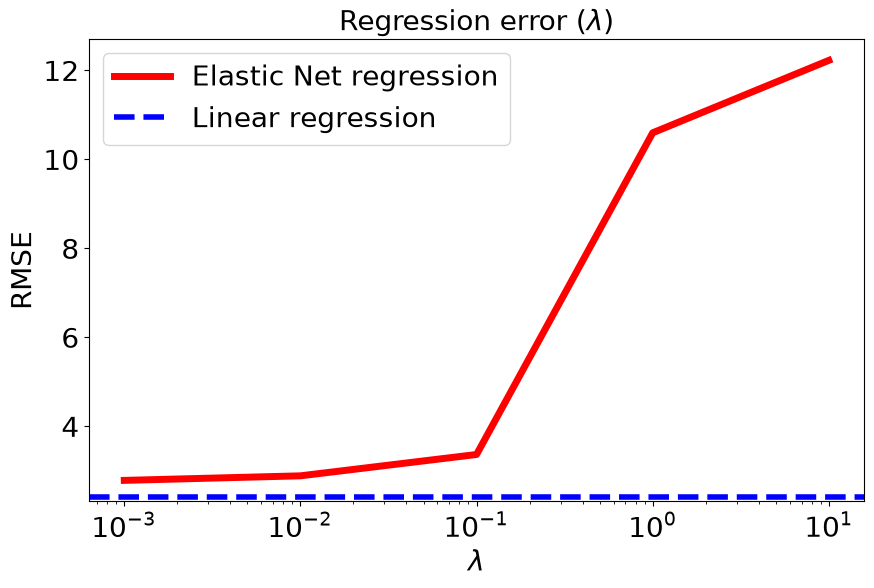

In [29]:
# recuperamos el error del modelo de regresión lineal sin regularizacion
baseline_error = root_mean_squared_error(y_true=y_test, y_pred=predicciones)

err_elastic = []
for a in alphas: # Para cada valor de alpha, entrenamos un modelo de Elastic Net
    elastic = ElasticNet(alpha=a, l1_ratio=elastic_net.l1_ratio_, max_iter=10000)
    elastic.fit(X_train_scaled, y_train)  
    y_pred = elastic.predict(X_test_scaled) # Calculamos las predicciones
    elastic_error = root_mean_squared_error(y_test, y_pred) # calculamos el error del conjunto de test
    err_elastic.append(elastic_error) # Guardamos el error en una lista

fig, ax = plt.subplots(figsize=(10, 6))
font = 20

ax.plot(alphas, err_elastic, linewidth=5, color="red", label="Elastic Net regression")
ax.axhline(baseline_error, linewidth=4, linestyle="--", color="blue", label="Linear regression")
ax.set_xscale("log")
ax.set_xlabel(r"$\lambda$", fontsize=font)
ax.set_ylabel("RMSE", fontsize=font)
ax.set_title(r"Regression error ($\lambda$)", fontsize=font)
ax.tick_params(labelsize=font)
ax.legend(fontsize=font)
plt.show()